# Learning from a calibration experiment

**Synthetic data, not laboratory results.** This notebook uses the same default data as the browser activity: seed 17 and noise standard deviation 0.055. It needs NumPy and Matplotlib. No data downloads, API keys, GPU, or LLM account are required.

We use validation data to explore model choices. This is not a final test-set evaluation. In a research project, reserve a separate final evaluation relevant to the intended use.

## 1. Generate the observations
Concentration `c` is in mmol/L. Absorbance `A` is dimensionless. The simulator assumes a linear relationship plus independent Gaussian noise. A real experiment may violate these assumptions.

Identify which arrays contain training observations and which contain validation observations.

In [1]:
import numpy as np
from numpy.polynomial import Polynomial
import matplotlib.pyplot as plt

# Synthetic teaching data, not experimental measurements.
# concentration: mmol/L; absorbance: dimensionless.
seed = 17
noise = 0.055
rng = np.random.default_rng(seed)
c_train = np.linspace(0.02, 0.98, 12)
A_train = 0.15 + 0.8 * c_train + rng.normal(0, noise, c_train.size)
c_validation = np.linspace(0.04, 0.96, 17)
A_validation = 0.15 + 0.8 * c_validation + rng.normal(0, noise, c_validation.size)

In [2]:
print("Training observations:", len(c_train))
print("Validation observations:", len(c_validation))
print("First pair:", c_train[0], A_train[0])

Training observations: 12
Validation observations: 17
First pair: 0.02 0.22656943494282156


## 2. Start with a baseline
The mean of the training responses gives a constant prediction. Do not use validation responses to fit this baseline. Predict whether a line should improve on it in this simulation.

In [3]:
def mse(prediction, observation):
    return np.mean((prediction - observation) ** 2)

baseline = A_train.mean()
print("Baseline value:", baseline)
print("Baseline training MSE:", mse(baseline, A_train))
print("Baseline validation MSE:", mse(baseline, A_validation))

Baseline value: 0.5245868950635898
Baseline training MSE: 0.05636839465122518
Baseline validation MSE: 0.04934309473862497


## 3. Fit a polynomial
Change `degree` from 1 to a larger value. `Polynomial.fit` fits by least squares and uses a scaled coordinate internally to improve numerical conditioning. It receives only the training observations. The degree is a model choice; the coefficients are fitted parameters.

In [4]:
degree = 1
model = Polynomial.fit(c_train, A_train, degree)
print("Training MSE:", mse(model(c_train), A_train))
print("Validation MSE:", mse(model(c_validation), A_validation))

Training MSE: 0.002866255565055143
Validation MSE: 0.005527110796245054


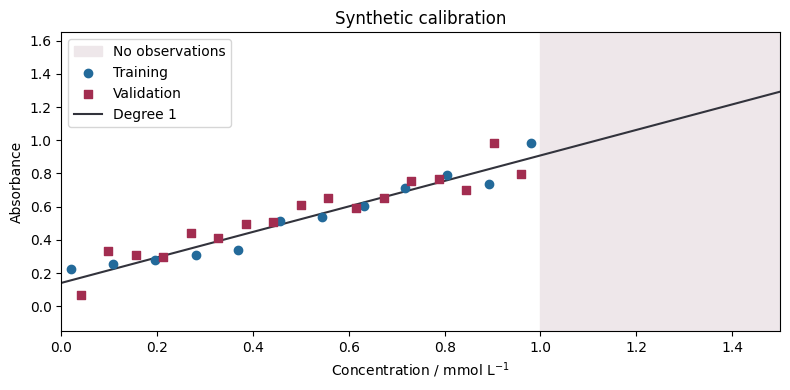

Prediction at 1.4 mmol/L: 1.2155774941824837


In [5]:
grid = np.linspace(0, 1.5, 181)
fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(1, 1.5, color="#eee7ea", label="No observations")
ax.scatter(c_train, A_train, label="Training", color="#236a9a", zorder=3)
ax.scatter(c_validation, A_validation, marker="s", label="Validation", color="#a22d50", zorder=3)
ax.plot(grid, model(grid), color="#32333c", label=f"Degree {degree}")
ax.set(xlabel="Concentration / mmol L$^{-1}$", ylabel="Absorbance",
       xlim=(0, 1.5), ylim=(-0.15, 1.65), title="Synthetic calibration")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
# The fixed axis can clip extreme predictions. Inspect numbers below as well.
print("Prediction at 1.4 mmol/L:", float(model(1.4)))

## 4. Compare the model choices
Before running, predict how the training error will change. Then compare with validation error. The validation measurements are being used for model selection, so their best score is not an unbiased final estimate for the selected procedure.

In [6]:
comparison = []
for d in range(1, 10):
    candidate = Polynomial.fit(c_train, A_train, d)
    train_error = mse(candidate(c_train), A_train)
    validation_error = mse(candidate(c_validation), A_validation)
    comparison.append((d, train_error, validation_error))
    print(f"degree={d}: train={train_error:.5f}, validation={validation_error:.5f}")

degree=1: train=0.00287, validation=0.00553
degree=2: train=0.00206, validation=0.00748
degree=3: train=0.00195, validation=0.00781
degree=4: train=0.00162, validation=0.00807
degree=5: train=0.00104, validation=0.00876
degree=6: train=0.00093, validation=0.00893
degree=7: train=0.00060, validation=0.00970
degree=8: train=0.00022, validation=0.00948
degree=9: train=0.00021, validation=0.00928


## 5. One controlled change
Change the `noise` value in the first code cell and run all cells again. Explain what happened to fitting and validation. This creates a new simulated experiment; it does not establish how a real instrument behaves.

Extension: repeat several seeds. Is the same degree selected every time? Do not choose a seed simply because it gives your preferred conclusion.

## 6. Check an assisted implementation
The following function is deliberately flawed for mean squared error. Calculate its output for residuals +1 and -1 before running it. An LLM may help explain or fix the code, but you must execute an independent check.

In [7]:
def flawed_score(prediction, observation):
    return ((prediction - observation).mean()) ** 2

p = np.array([2.0, 0.0])
y = np.array([1.0, 1.0])
print("Flawed score:", flawed_score(p, y))
print("Mean squared error:", mse(p, y))
assert np.isclose(mse(p, y), 1.0)
assert np.isclose(mse(y, y), 0.0)

Flawed score: 0.0
Mean squared error: 1.0


## Submit a short interpretation
1. State the model choice and the evidence for it.
2. Explain which data fitted parameters and which data influenced model selection.
3. State one assumption needed to use the calibration elsewhere.
4. Propose an additional measurement or final evaluation.
5. If you used an LLM, record a consequential suggestion and how you checked it.

Restart the kernel and run all cells before sharing the notebook. Save your work under a new filename.